In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
from matplotlib.collections import LineCollection
from matplotlib.colors import TwoSlopeNorm
from matplotlib.lines import Line2D
from pybonsai import BonsaiOutput
from scipy.spatial.distance import squareform
from tqdm import tqdm

import bonsai_loop as bl
from bonsai_loop.bonsai_lib import get_pdists_on_tree_euclidean, get_pdists_posterior

sc.set_figure_params(figsize=(5, 5))

/home/stan/Git/bonsai-loop/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


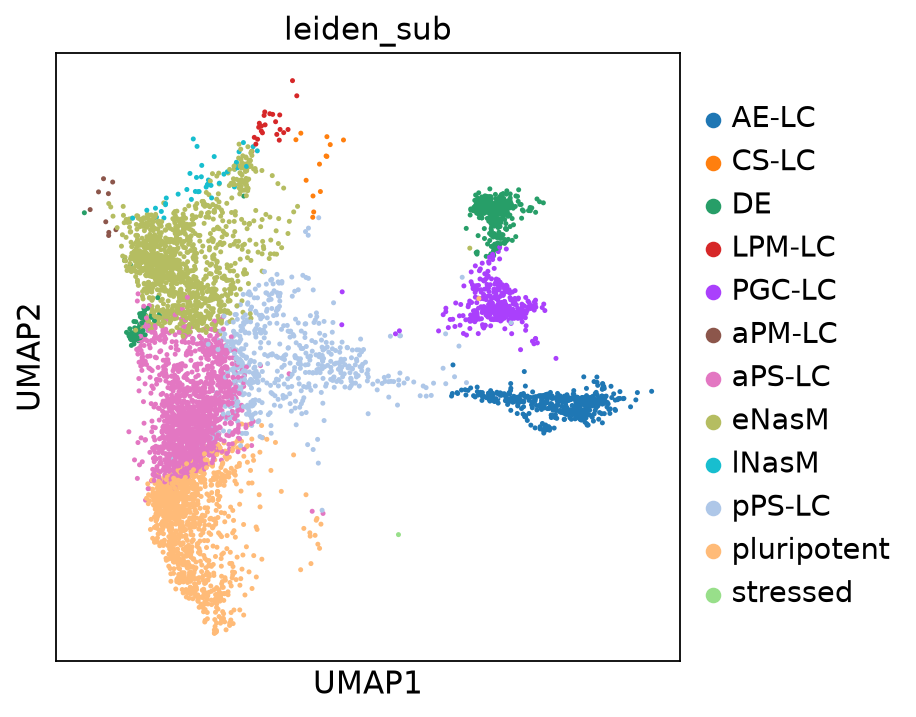

In [2]:
adata = sc.read_h5ad("../data/48h-1/adata_48h_hvg_raw.h5ad")
meta = pd.read_csv("../data/48h-1/adata_timeseries_old_48h-1_meta.csv", index_col=0)
adata.obs = meta.loc[adata.obs.index]
adata.obsm["X_umap"] = np.array(
    adata.obs.loc[:, ["umap_old_48-96h_x", "umap_old_48-96h_y"]]
)
sc.pl.umap(adata, color=["leiden_sub"])
del meta

# Full data

In [3]:
BONSAI_DIR = Path("../data/48h-1/adata_48h_hvg_raw_sanity_bonsai/final_bonsai_tree")
ROOT_CELL = "AAGGAATAGAGCAGTC-1_48h"

out = BonsaiOutput(BONSAI_DIR)
node_index = {node_id: i for i, node_id in enumerate(out.node_ids)}
tree = bl.bonsai_lib.Layout_Tree()
tree.from_newick(
    (BONSAI_DIR / "tree.nwk").read_text().strip(), node_id_to_vert_ind=node_index
)
tree.root.storeParent()
if ROOT_CELL is not None:
    root_node = tree.get_vert_ind_to_node_DF()[node_index[ROOT_CELL]].parentNode
    tree.reset_root(root_node.vert_ind)
print(
    f"{int(out.is_sample.sum())} leaves, {out.n_nodes} nodes, {out.n_features} genes; "
    f"root {tree.root.nodeId!r} with {len(tree.root.childNodes)} children"
)

5927 leaves, 11636 nodes, 480 genes; root 'internal_node_9396' with 3 children


In [4]:
LABEL_KEY = "leiden_sub"

node_data_lookup = bl.convergence.compute_tree_node_level_and_label(
    tree=tree,
    node_level_type="topological",
    label_lookup_leaves=adata.obs[LABEL_KEY].to_dict(),
)
bl.convergence.compute_bonsai_tree_dendrogram(
    tree=tree,
    node_data_lookup=node_data_lookup,
    ladderize_by_annotated_leaves_only=True,
)

compute depth-first ordering of nodes
root node internal_node_9396
compute node level and label


11636it [00:00, 463137.07it/s]


In [5]:
gas_bonsai_output_folder = BONSAI_DIR
gas_cell_ids = adata.obs.index.to_list()

gas_euclidean_distances_straight = squareform(
    get_pdists_posterior(
        bonsai_output_folder=gas_bonsai_output_folder,
        cell_ids=gas_cell_ids,
    )
)
gas_euclidean_distances_tree = squareform(
    get_pdists_on_tree_euclidean(
        nwk_file=gas_bonsai_output_folder / "tree.nwk",
        bonsai_output_folder=gas_bonsai_output_folder,
        cell_ids=gas_cell_ids,
    )
)

## Deviation score towards DE

In [7]:
# pick a DE reference
reference_node_id = adata.obs[adata.obs["leiden_sub"] == "DE"].index[10]

# compute delta deviation scores for all branches
# here we set normalize_by_branch_length=False in order to accumulate deviation scores
bl.convergence.compute_delta_deviation_from_parent(
    node_data_lookup=node_data_lookup,
    reference_node_ids=[reference_node_id],
    normalize_by_branch_length=False,
    bonsai_output_folder=gas_bonsai_output_folder,
)

deviation_loop_up = {}
for leaf_node_id in tqdm(gas_cell_ids):
    n_steps = 1
    straight_dist_leaf = gas_euclidean_distances_straight[
        np.array(gas_cell_ids) == leaf_node_id,
        np.array(gas_cell_ids) == reference_node_id,
    ][0]
    tree_dist_leaf = gas_euclidean_distances_tree[
        np.array(gas_cell_ids) == leaf_node_id,
        np.array(gas_cell_ids) == reference_node_id,
    ][0]
    deviation_score_leaf = tree_dist_leaf - straight_dist_leaf
    deviation_loop_up[leaf_node_id] = deviation_score_leaf
    while True:
        try:
            acc_score, end_node_id = (
                bl.convergence.accumulate_delta_deviation_scores_along_lineage(
                    node_data_lookup=node_data_lookup,
                    source_node_id=leaf_node_id,
                    reference_node_id=reference_node_id,
                    n_steps=n_steps,
                    direction="up",
                )
            )
            deviation_loop_up[end_node_id] = acc_score + deviation_score_leaf
        except Exception:
            break
        n_steps += 1

compute deviations for 11635 branches × 1 refs


100%|██████████| 5927/5927 [00:11<00:00, 494.66it/s]


# Cellstates

In [8]:
cs_bonsai_output_folder = Path(
    "../data/48h-1/adata_48h_hvg_raw_cellstates_sanity_bonsai/final_bonsai_tree"
)

# every leaf of this tree is a cellstate, labelled with the most common label of its cells
cs_cell_to_cs = pd.read_csv(
    "../data/48h-1/adata_48h_hvg_raw_cellstates/cell_id_to_cs_id.csv",
    header=None,
    index_col=0,
)[1]
cs_leaf_labels = (
    adata.obs[LABEL_KEY]
    .groupby(cs_cell_to_cs.loc[adata.obs.index].to_numpy())
    .agg(lambda labels: labels.value_counts().idxmax())
    .astype(adata.obs[LABEL_KEY].dtype)
)
# the cellstates that hold the root cell and the DE reference of the full data
cs_root_cell = cs_cell_to_cs[ROOT_CELL]
cs_reference_node_id = cs_cell_to_cs[reference_node_id]

cs_out = BonsaiOutput(cs_bonsai_output_folder)
cs_node_index = {node_id: i for i, node_id in enumerate(cs_out.node_ids)}
cs_tree = bl.bonsai_lib.Layout_Tree()
cs_tree.from_newick(
    (cs_bonsai_output_folder / "tree.nwk").read_text().strip(),
    node_id_to_vert_ind=cs_node_index,
)
cs_tree.root.storeParent()
cs_root_node = cs_tree.get_vert_ind_to_node_DF()[cs_node_index[cs_root_cell]].parentNode
cs_tree.reset_root(cs_root_node.vert_ind)
print(
    f"{int(cs_out.is_sample.sum())} leaves, {cs_out.n_nodes} nodes, {cs_out.n_features} genes; "
    f"root {cs_tree.root.nodeId!r} with {len(cs_tree.root.childNodes)} children"
)
print(
    f"reference {cs_reference_node_id!r}: {int((cs_cell_to_cs == cs_reference_node_id).sum())} cells, "
    f"label {cs_leaf_labels[cs_reference_node_id]}"
)

1045 leaves, 2088 nodes, 860 genes; root 'internal_node_1231' with 3 children
reference 'cs_811': 26 cells, label DE


In [9]:
cs_node_data_lookup = bl.convergence.compute_tree_node_level_and_label(
    tree=cs_tree,
    node_level_type="topological",
    label_lookup_leaves=cs_leaf_labels.to_dict(),
)
bl.convergence.compute_bonsai_tree_dendrogram(
    tree=cs_tree,
    node_data_lookup=cs_node_data_lookup,
    ladderize_by_annotated_leaves_only=True,
)

compute depth-first ordering of nodes
root node internal_node_1231
compute node level and label


2088it [00:00, 320983.24it/s]


In [10]:
cs_cell_ids = cs_leaf_labels.index.to_list()

cs_euclidean_distances_straight = squareform(
    get_pdists_posterior(
        bonsai_output_folder=cs_bonsai_output_folder,
        cell_ids=cs_cell_ids,
    )
)
cs_euclidean_distances_tree = squareform(
    get_pdists_on_tree_euclidean(
        nwk_file=cs_bonsai_output_folder / "tree.nwk",
        bonsai_output_folder=cs_bonsai_output_folder,
        cell_ids=cs_cell_ids,
    )
)

## Deviation score towards DE

In [11]:
bl.convergence.compute_delta_deviation_from_parent(
    node_data_lookup=cs_node_data_lookup,
    reference_node_ids=[cs_reference_node_id],
    normalize_by_branch_length=False,
    bonsai_output_folder=cs_bonsai_output_folder,
)

cs_deviation_loop_up = {}
for leaf_node_id in tqdm(cs_cell_ids):
    n_steps = 1
    straight_dist_leaf = cs_euclidean_distances_straight[
        np.array(cs_cell_ids) == leaf_node_id,
        np.array(cs_cell_ids) == cs_reference_node_id,
    ][0]
    tree_dist_leaf = cs_euclidean_distances_tree[
        np.array(cs_cell_ids) == leaf_node_id,
        np.array(cs_cell_ids) == cs_reference_node_id,
    ][0]
    deviation_score_leaf = tree_dist_leaf - straight_dist_leaf
    cs_deviation_loop_up[leaf_node_id] = deviation_score_leaf
    while True:
        try:
            acc_score, end_node_id = (
                bl.convergence.accumulate_delta_deviation_scores_along_lineage(
                    node_data_lookup=cs_node_data_lookup,
                    source_node_id=leaf_node_id,
                    reference_node_id=cs_reference_node_id,
                    n_steps=n_steps,
                    direction="up",
                )
            )
            cs_deviation_loop_up[end_node_id] = acc_score + deviation_score_leaf
        except Exception:
            break
        n_steps += 1

compute deviations for 2087 branches × 1 refs


100%|██████████| 1045/1045 [00:00<00:00, 2135.91it/s]


# Plot

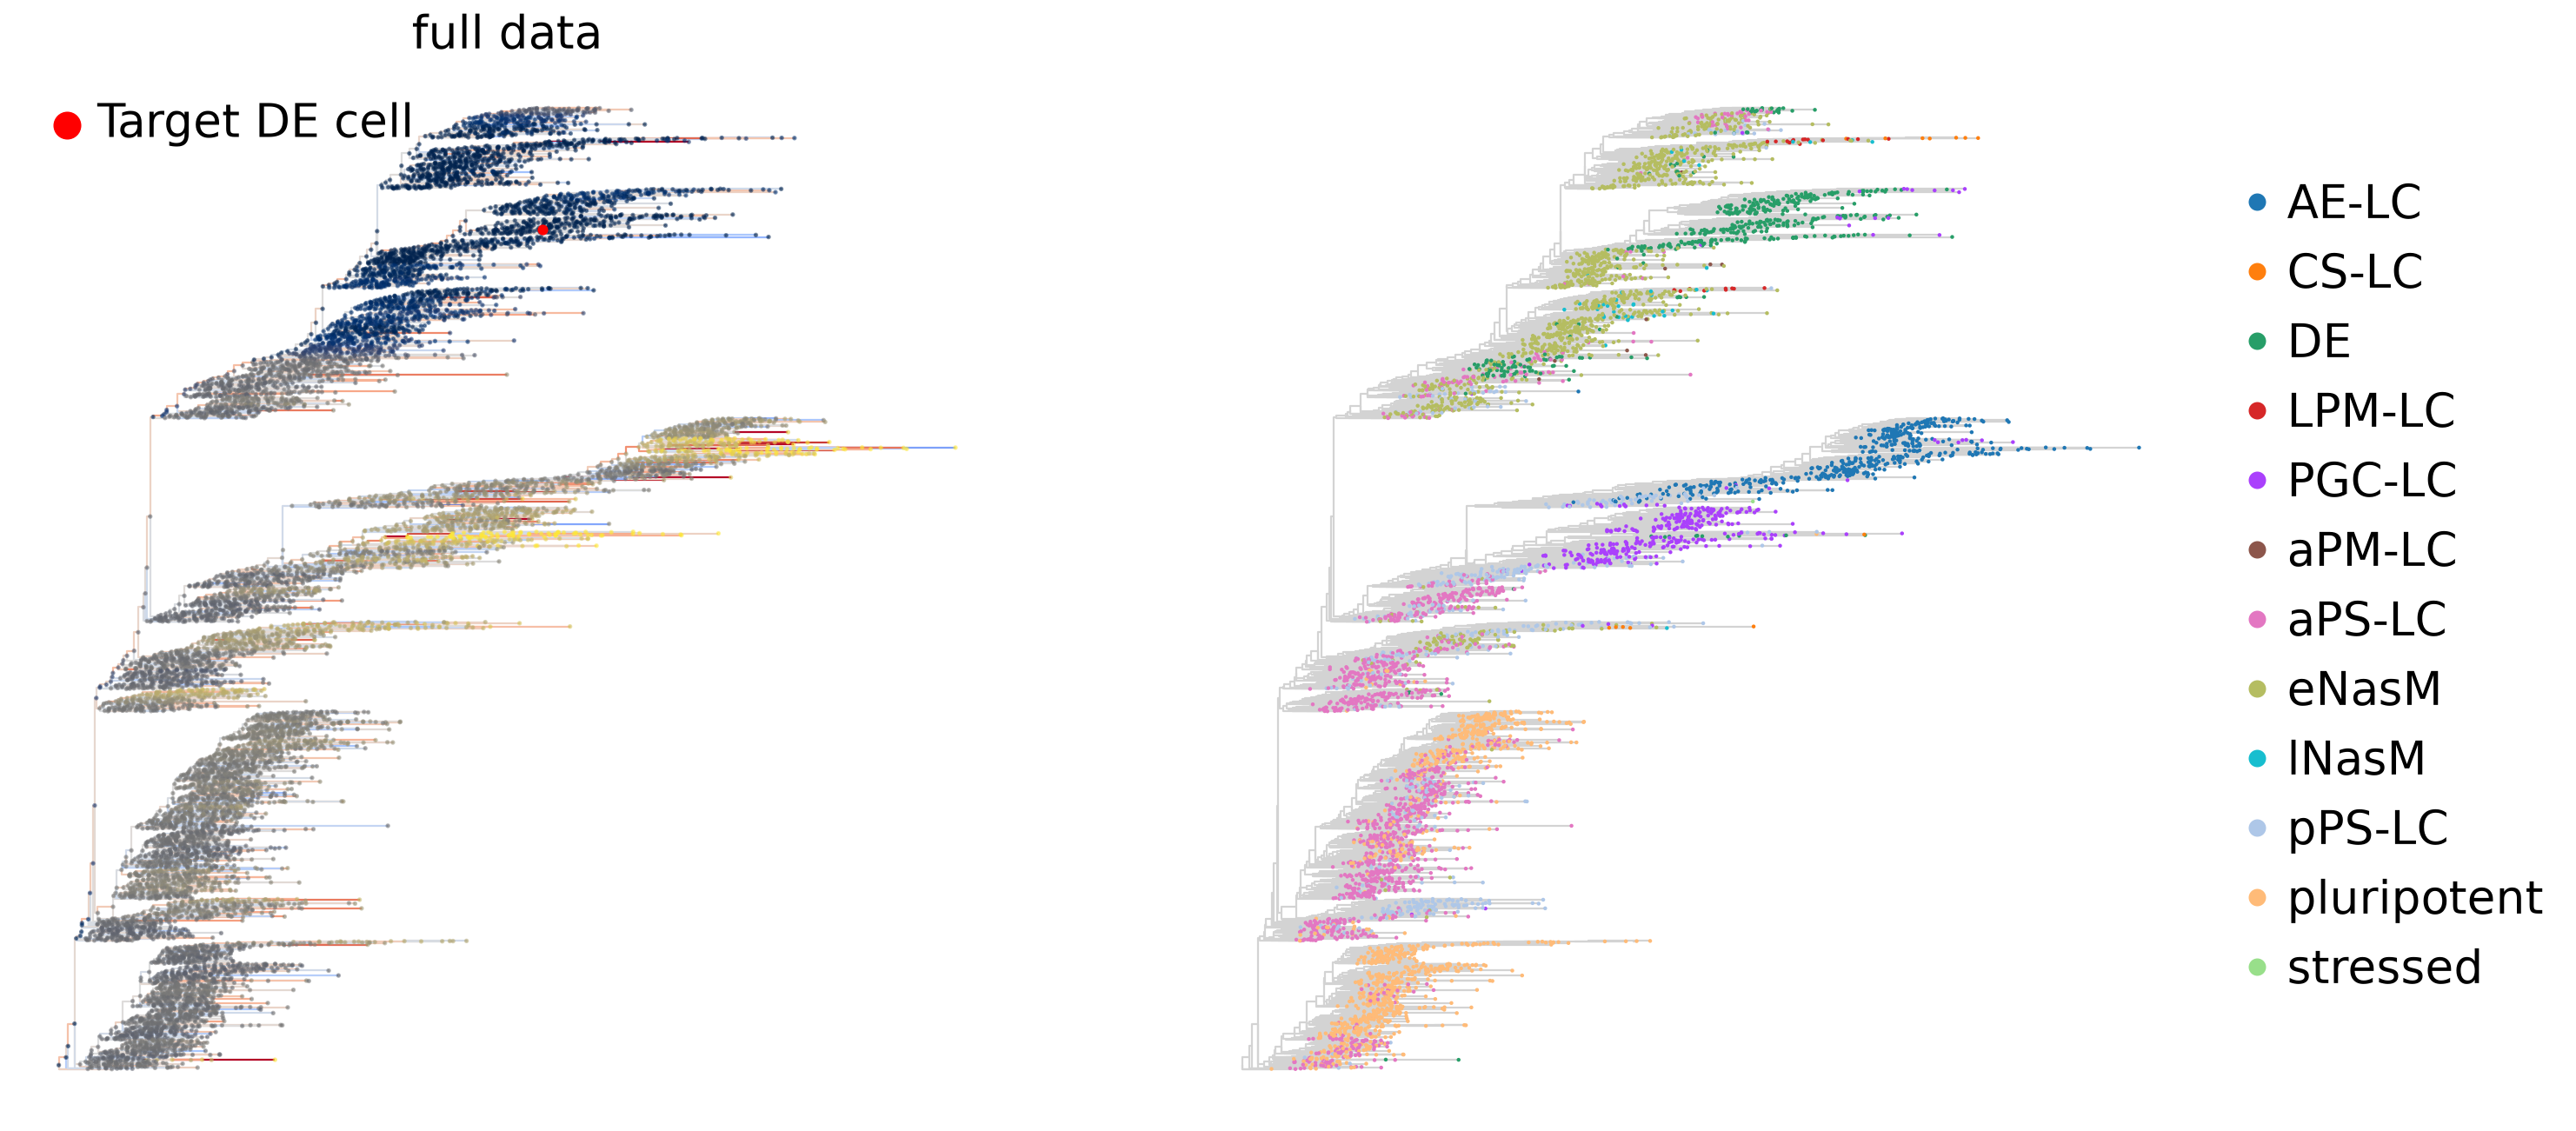

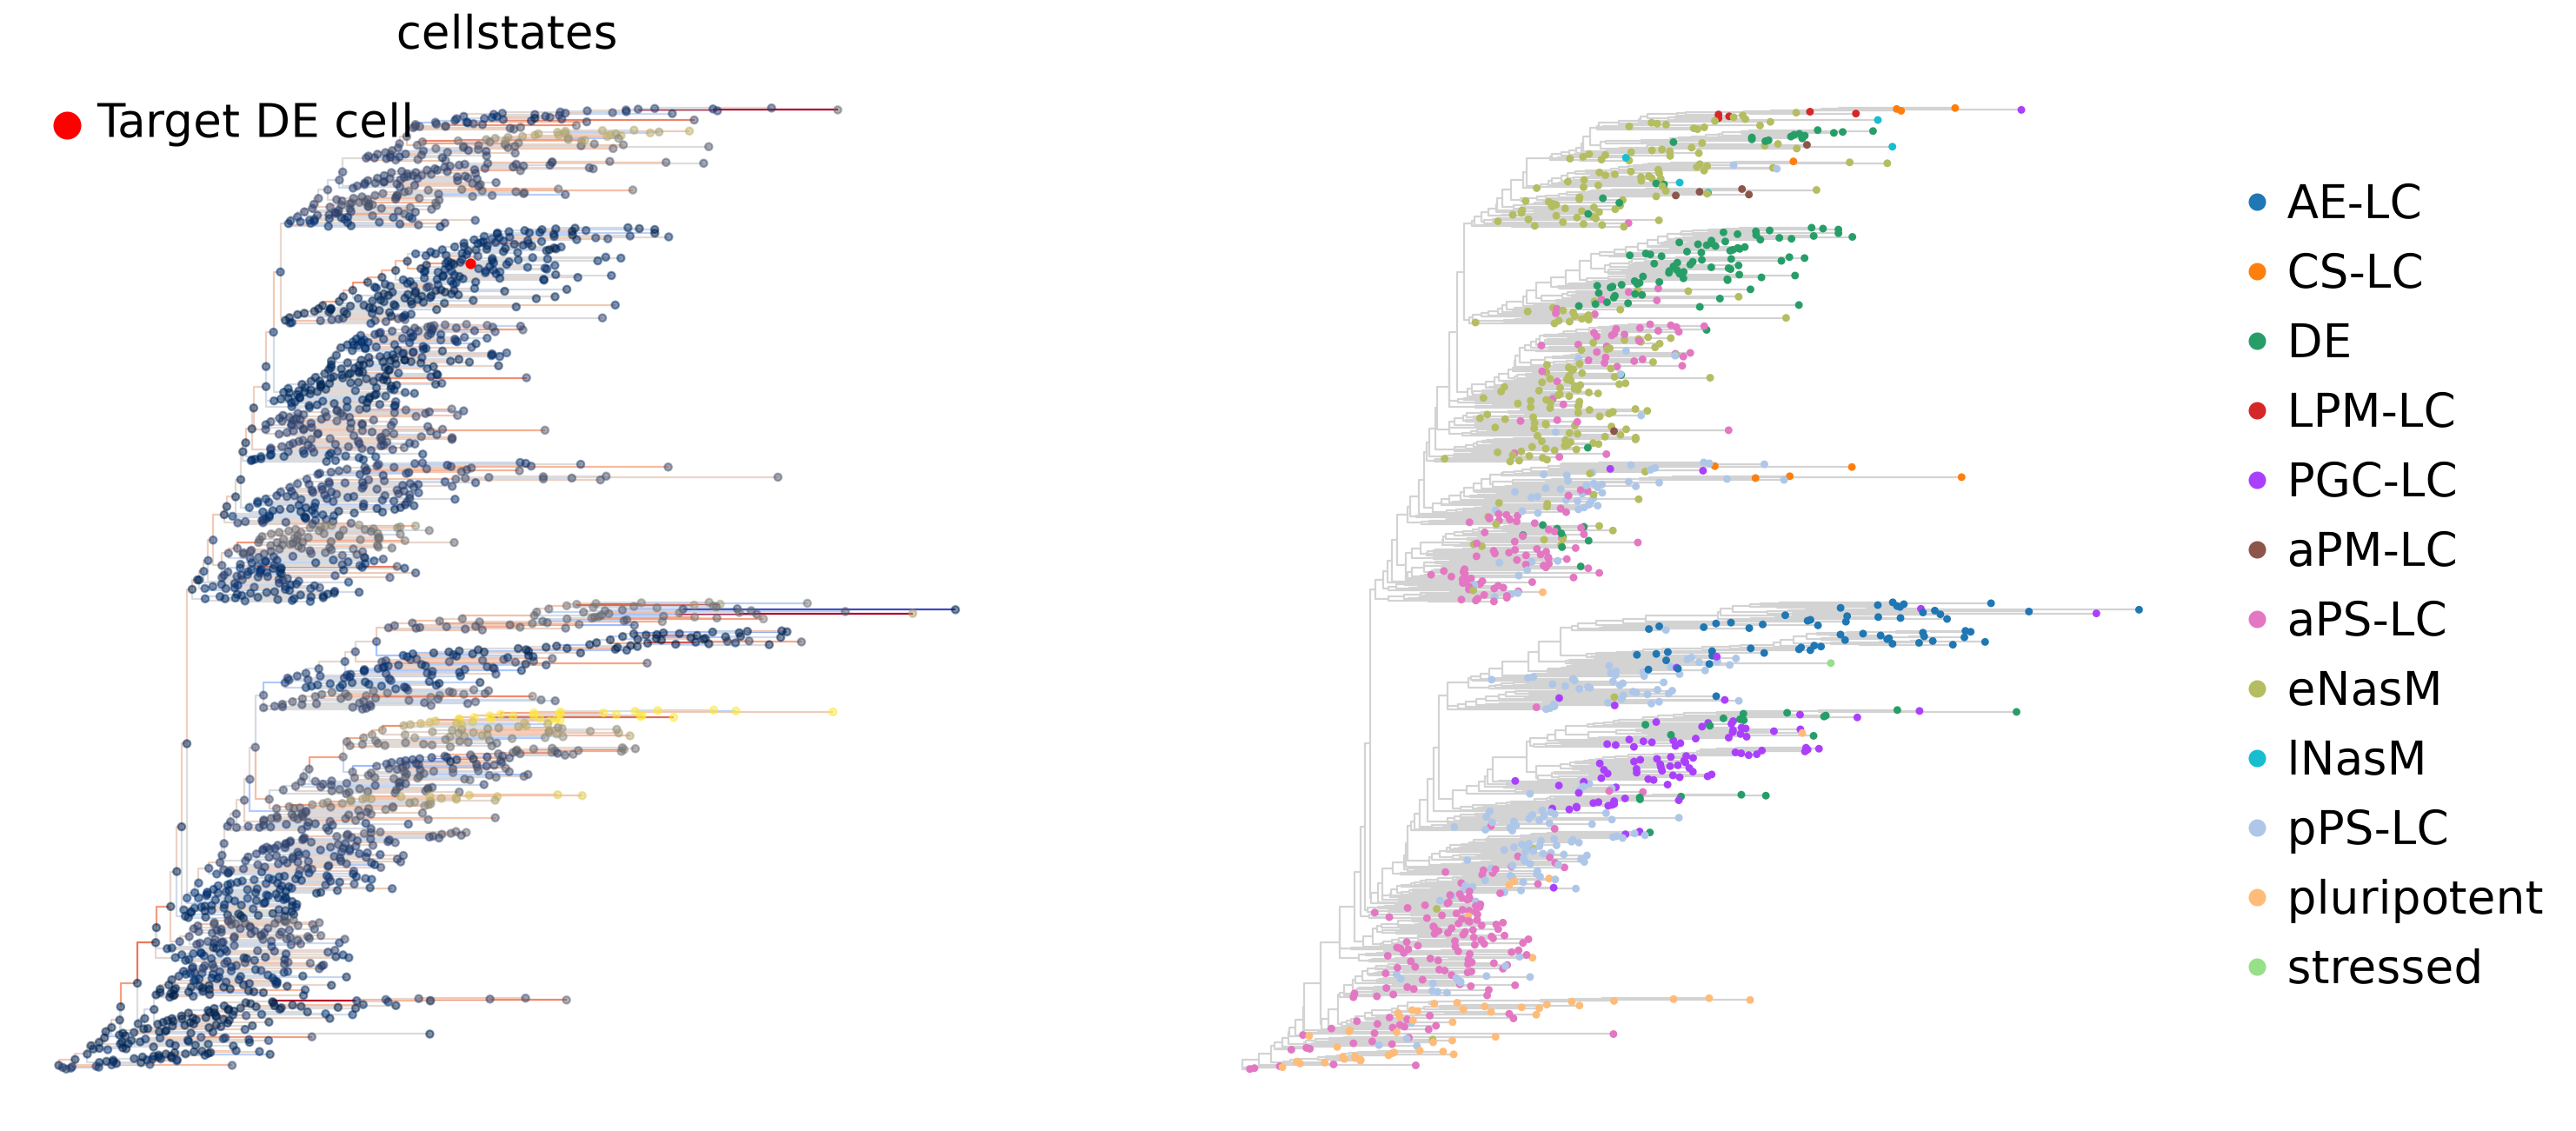

In [26]:
gas_cell_types = pd.Categorical(adata.obs["leiden_sub"]).categories
gas_colors = adata.uns["leiden_sub_colors"]
color_pal = dict(zip(gas_cell_types, gas_colors))

panels = [
    {
        "title": "full data",
        "node_data_lookup": node_data_lookup,
        "deviation_loop_up": deviation_loop_up,
        "reference_node_id": reference_node_id,
        "leaf_labels": adata.obs["leiden_sub"],
        "node_size": 2,
        "leaf_size": 4,
    },
    {
        "title": "cellstates",
        "node_data_lookup": cs_node_data_lookup,
        "deviation_loop_up": cs_deviation_loop_up,
        "reference_node_id": cs_reference_node_id,
        "leaf_labels": cs_leaf_labels,
        "node_size": 14,
        "leaf_size": 16,
    },
]

for panel in panels:
    panel_node_data_lookup = panel["node_data_lookup"]
    panel_deviation_loop_up = panel["deviation_loop_up"]
    panel_reference_node_id = panel["reference_node_id"]

    # plot dendrogram
    xy = {
        nid: panel_node_data_lookup[nid].dendrogram_coords
        for nid in panel_node_data_lookup
    }
    segs, edge_vals = [], []
    for child_id in panel_deviation_loop_up.keys():
        parent = panel_node_data_lookup[child_id].tree_node.parentNode
        if parent is None:
            continue
        parent_id = parent.nodeId
        px, py = xy[parent_id]
        cx, cy = xy[child_id]
        segs.append([(px, py), (px, cy), (cx, cy)])
        edge_vals.append(
            panel_node_data_lookup[child_id].delta_deviation_from_parent[
                panel_reference_node_id
            ]
        )
    edge_vals = np.array(edge_vals)
    deviation_xy = [panel_deviation_loop_up[nid] for nid in xy.keys()]
    xy = np.array(list(xy.values()))
    xy_reference = panel_node_data_lookup[panel_reference_node_id].dendrogram_coords

    cell_ids = [
        nid for nid, nd in panel_node_data_lookup.items() if nd.tree_node.isLeaf
    ]
    cell_xy = np.array(
        [panel_node_data_lookup[cid].dendrogram_coords for cid in cell_ids]
    )
    cell_colors = [color_pal[panel["leaf_labels"][cid]] for cid in cell_ids]

    fig, axes = plt.subplots(1, 2, figsize=(20, 10))
    ax = axes[0]
    elim = np.percentile(np.abs(edge_vals), 99.9)
    lc = LineCollection(
        segs,
        cmap="coolwarm",
        norm=TwoSlopeNorm(vmin=-elim, vcenter=0.0, vmax=elim),
        linewidths=1,
        zorder=1,
    )
    lc.set_array(edge_vals)
    ax.add_collection(lc)
    cmin, cmax = np.percentile(deviation_xy, [10, 99])
    ax.scatter(
        xy[:, 0],
        xy[:, 1],
        c=deviation_xy,
        cmap="cividis",
        vmin=cmin,
        vmax=cmax,
        s=panel["node_size"],
        zorder=2,
        alpha=0.5,
    )
    ax.scatter(
        xy_reference[0],
        xy_reference[1],
        c="red",
        s=20,
        zorder=3,
        label="Target DE cell",
    )
    ax.legend(loc="upper left", frameon=False, fontsize=24, markerscale=3)
    ax.set_title(panel["title"], fontsize=24)
    ax.grid(False)
    ax.set_axis_off()
    ax = axes[1]
    lc = LineCollection(
        segs,
        linewidths=1,
        zorder=1,
    )
    lc.set_color("lightgray")
    ax.add_collection(lc)

    ax.scatter(
        cell_xy[:, 0],
        cell_xy[:, 1],
        c=cell_colors,
        s=panel["leaf_size"],
        lw=0,
        zorder=2,
    )
    legend_handles = [
        Line2D(
            [0],
            [0],
            marker="o",
            color="w",
            markerfacecolor=color_pal[ct],
            markersize=10,
            linestyle="",
            label=ct,
        )
        for ct in gas_cell_types
    ]
    ax.legend(
        handles=legend_handles,
        loc="center left",
        bbox_to_anchor=(1.02, 0.5),
        frameon=False,
        fontsize=24,
    )
    ax.grid(False)
    ax.set_axis_off()
    plt.show()

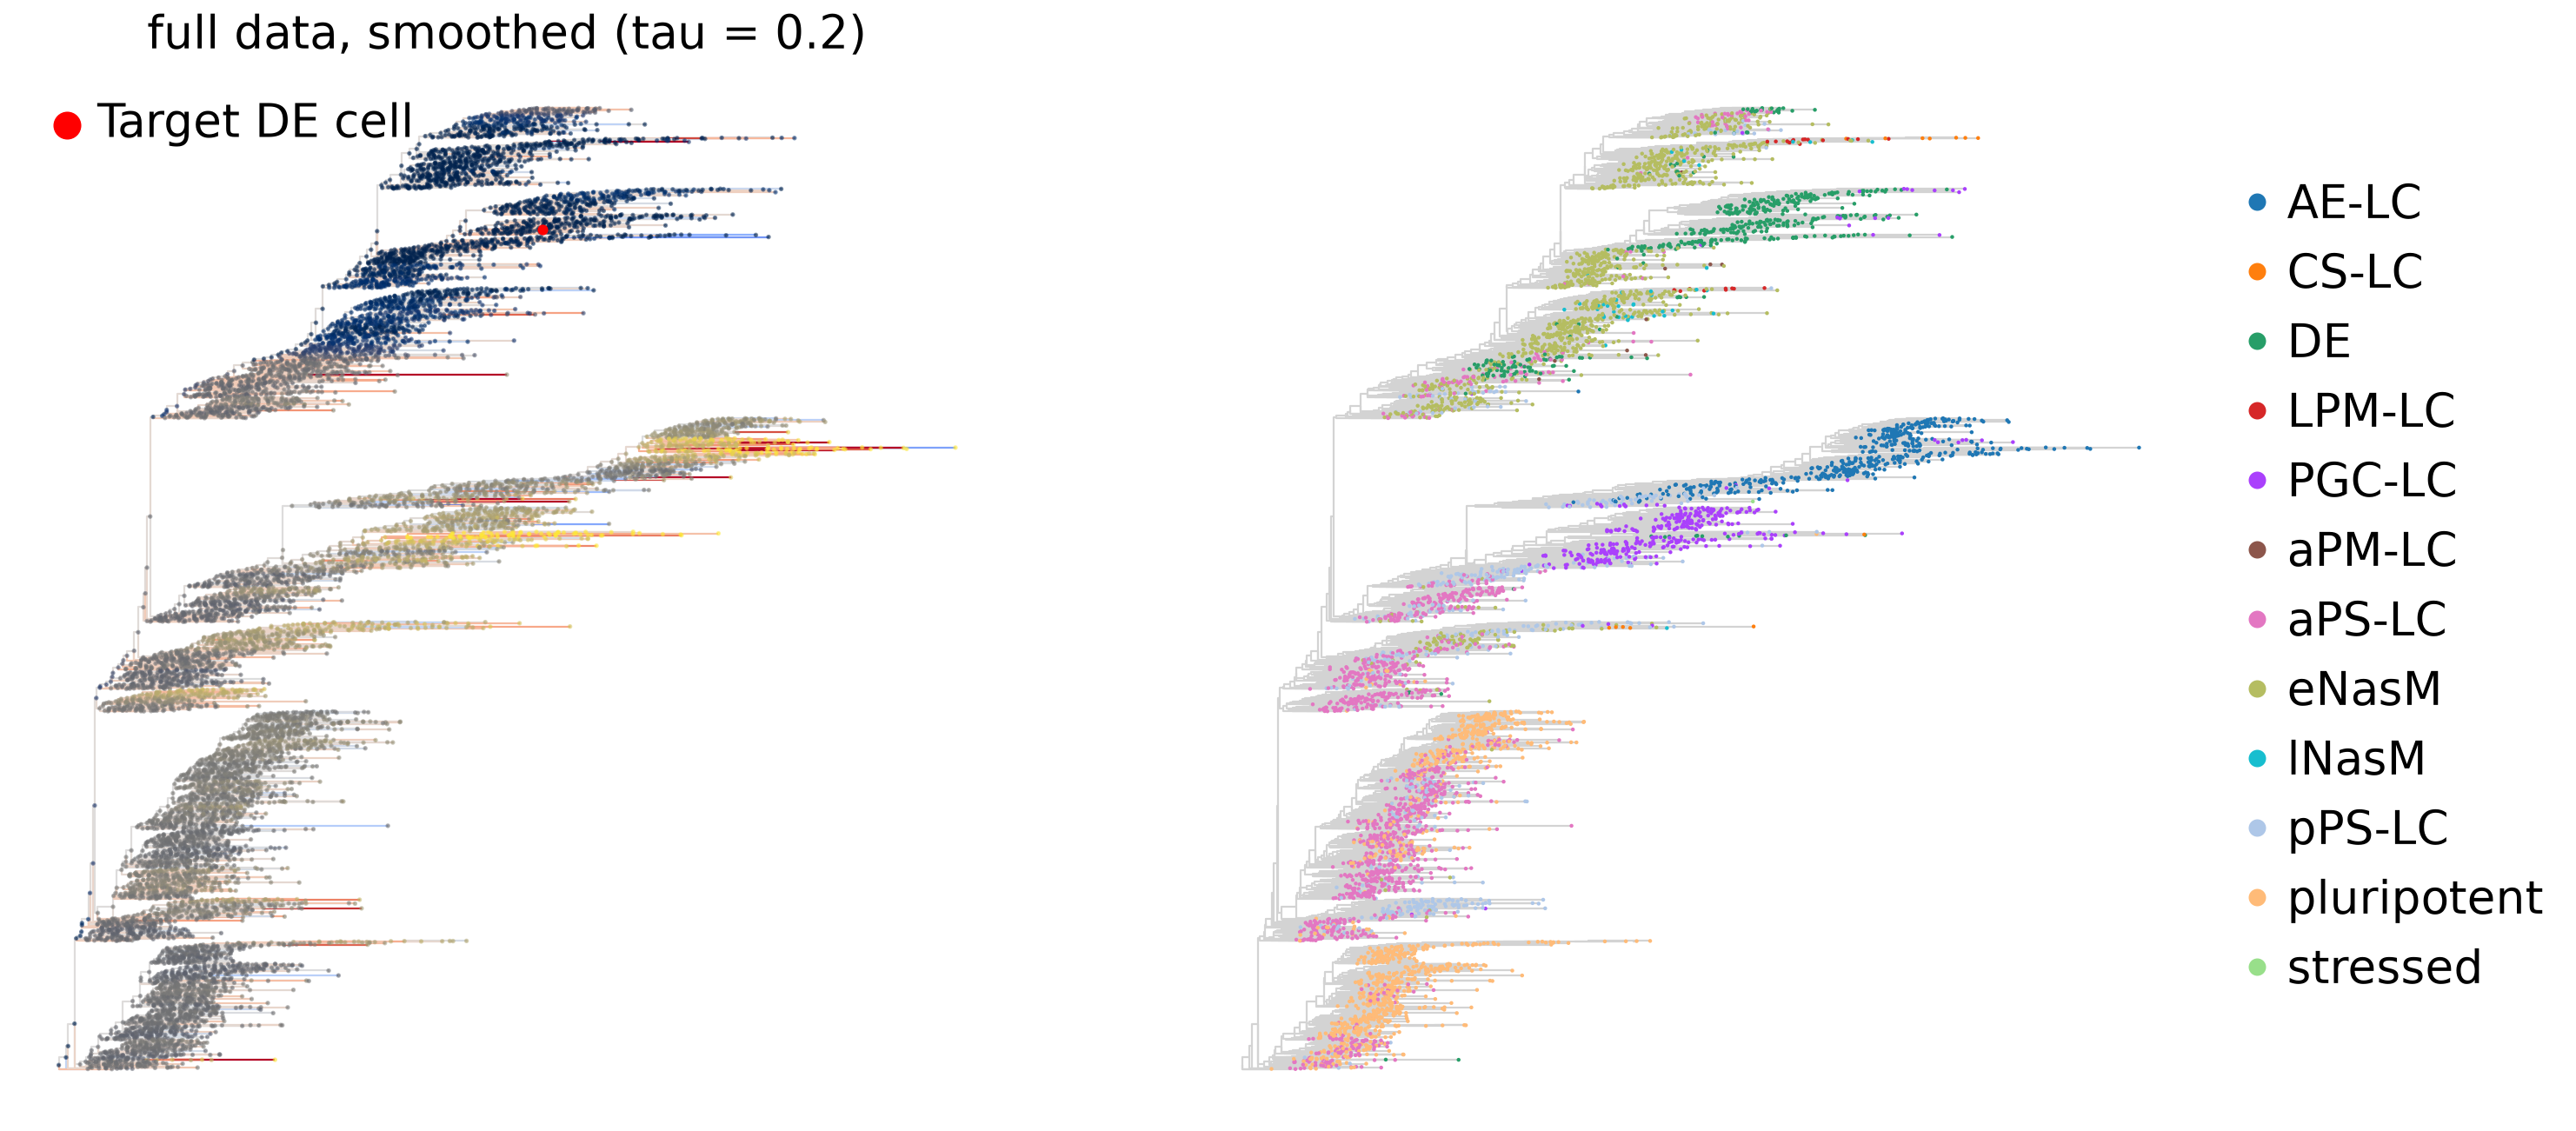

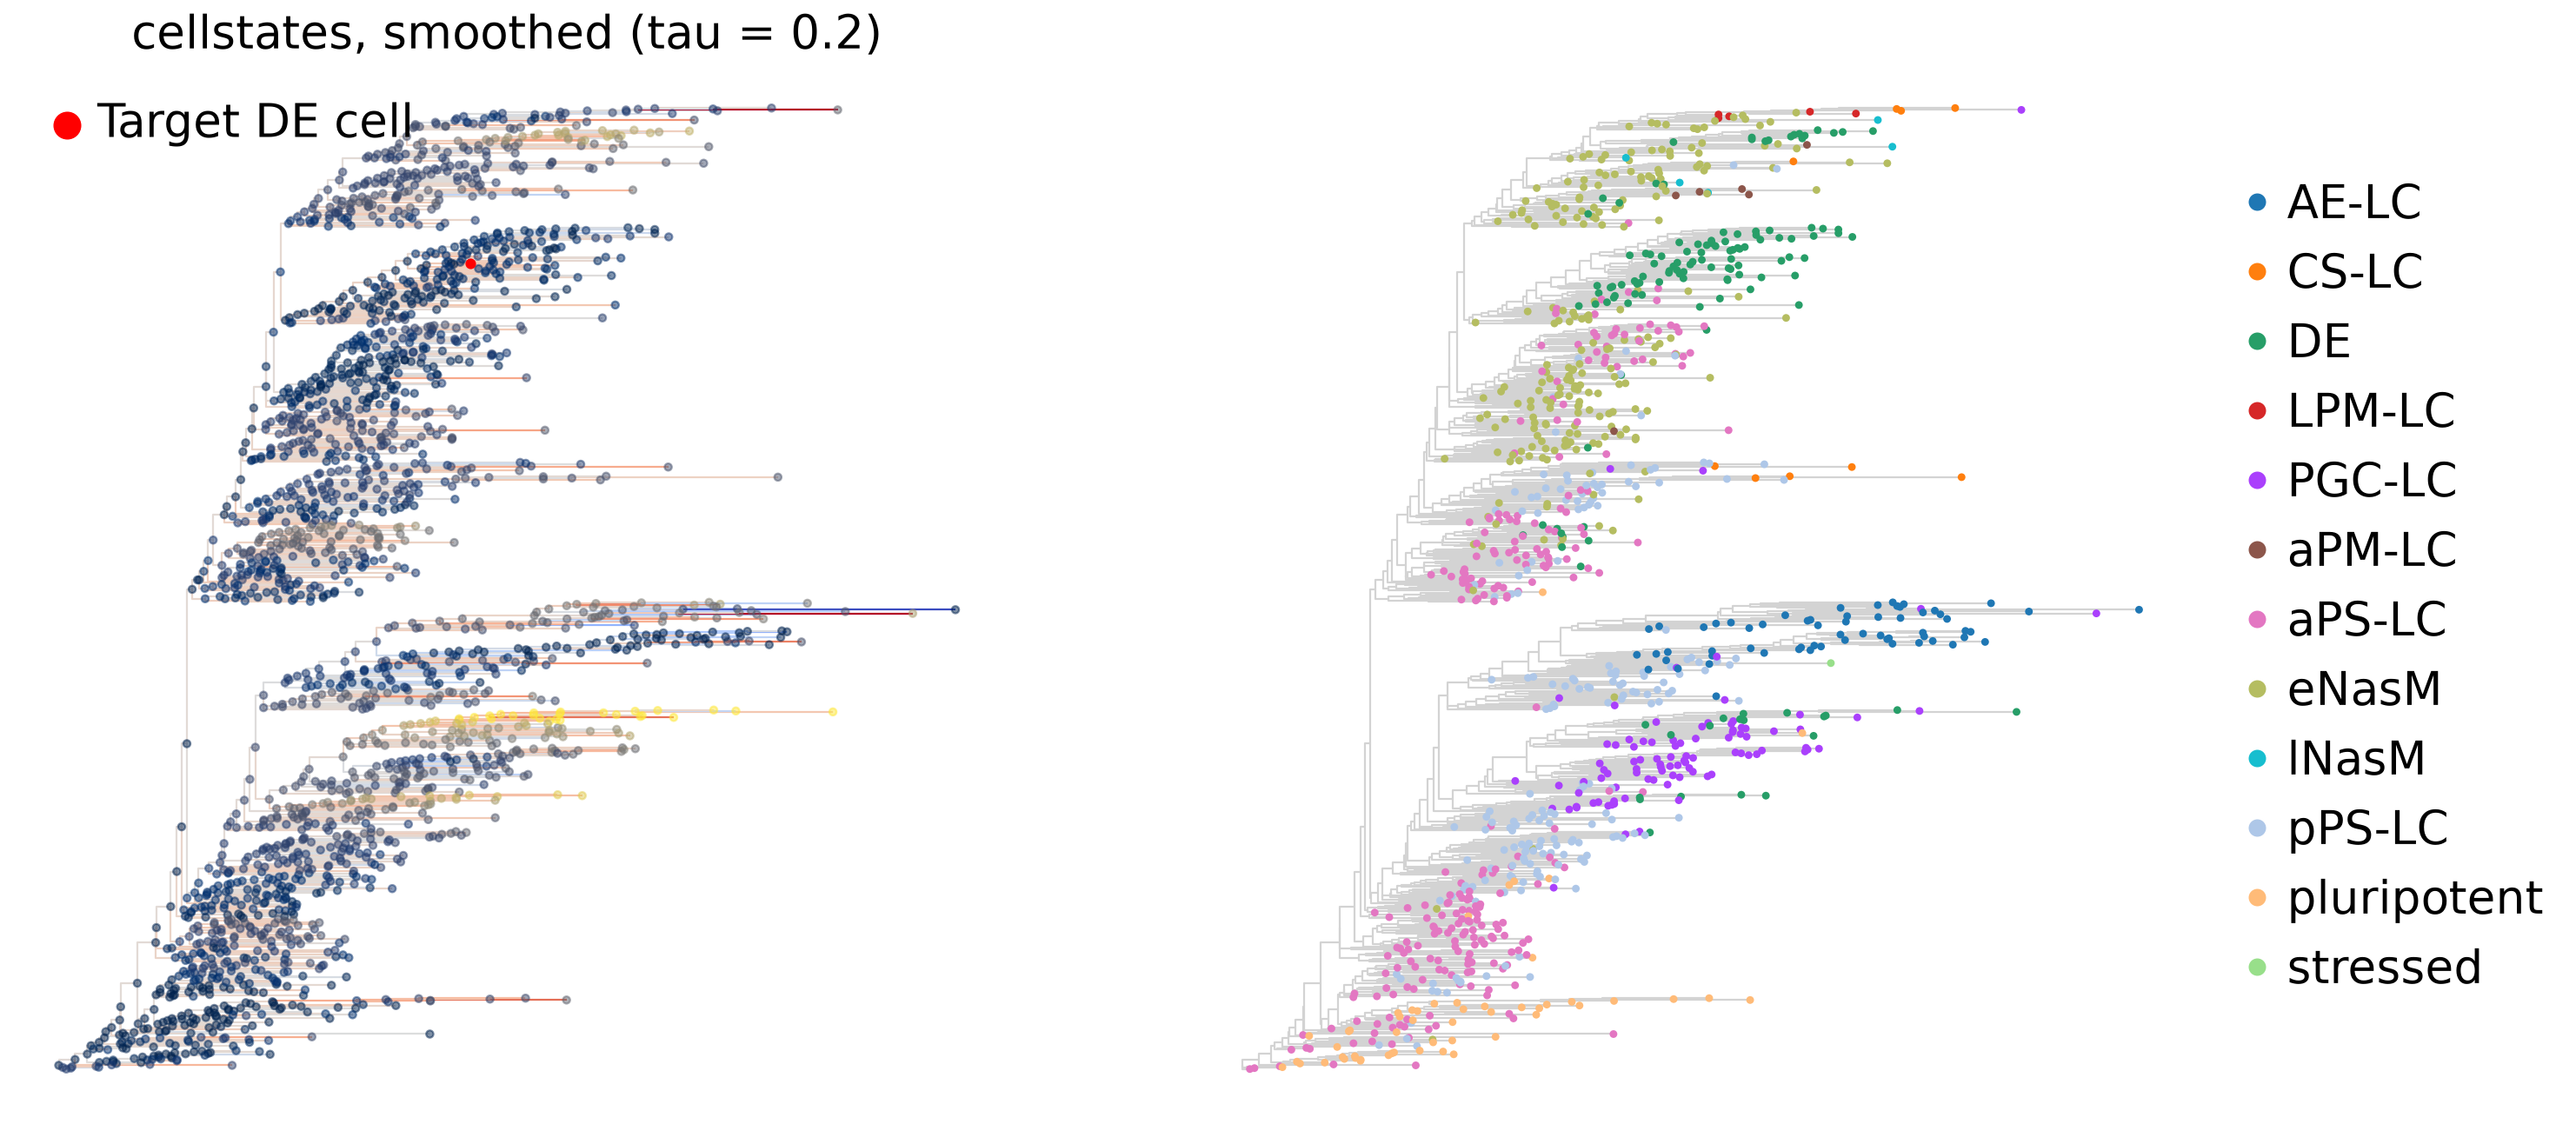

In [27]:
tau = 0.2  # exponential kernel length of the smoothing, in branch length
cutoff_multiplier = (
    3.0  # branches further away than cutoff_multiplier * tau are ignored
)

for panel in panels:
    panel_node_data_lookup = panel["node_data_lookup"]
    panel_deviation_loop_up = panel["deviation_loop_up"]
    panel_reference_node_id = panel["reference_node_id"]

    # smooth delta deviation scores over neighboring branches
    bl.convergence.smoothen_delta_deviation(
        node_data_lookup=panel_node_data_lookup,
        reference_node_ids=[panel_reference_node_id],
        tau=tau,
        cutoff_multiplier=cutoff_multiplier,
        normalize=True,
    )

    # plot dendrogram
    xy = {
        nid: panel_node_data_lookup[nid].dendrogram_coords
        for nid in panel_node_data_lookup
    }
    segs, edge_vals = [], []
    for child_id in panel_deviation_loop_up.keys():
        parent = panel_node_data_lookup[child_id].tree_node.parentNode
        if parent is None:
            continue
        parent_id = parent.nodeId
        px, py = xy[parent_id]
        cx, cy = xy[child_id]
        segs.append([(px, py), (px, cy), (cx, cy)])
        edge_vals.append(
            panel_node_data_lookup[child_id].delta_deviation_from_parent_smooth[
                panel_reference_node_id
            ]
        )
    edge_vals = np.array(edge_vals)
    deviation_xy = [panel_deviation_loop_up[nid] for nid in xy.keys()]
    xy = np.array(list(xy.values()))
    xy_reference = panel_node_data_lookup[panel_reference_node_id].dendrogram_coords

    cell_ids = [
        nid for nid, nd in panel_node_data_lookup.items() if nd.tree_node.isLeaf
    ]
    cell_xy = np.array(
        [panel_node_data_lookup[cid].dendrogram_coords for cid in cell_ids]
    )
    cell_colors = [color_pal[panel["leaf_labels"][cid]] for cid in cell_ids]

    fig, axes = plt.subplots(1, 2, figsize=(20, 10))
    ax = axes[0]
    elim = np.percentile(np.abs(edge_vals), 99.9)
    lc = LineCollection(
        segs,
        cmap="coolwarm",
        norm=TwoSlopeNorm(vmin=-elim, vcenter=0.0, vmax=elim),
        linewidths=1,
        zorder=1,
    )
    lc.set_array(edge_vals)
    ax.add_collection(lc)
    cmin, cmax = np.percentile(deviation_xy, [10, 99])
    ax.scatter(
        xy[:, 0],
        xy[:, 1],
        c=deviation_xy,
        cmap="cividis",
        vmin=cmin,
        vmax=cmax,
        s=panel["node_size"],
        zorder=2,
        alpha=0.5,
    )
    ax.scatter(
        xy_reference[0],
        xy_reference[1],
        c="red",
        s=20,
        zorder=3,
        label="Target DE cell",
    )
    ax.legend(loc="upper left", frameon=False, fontsize=24, markerscale=3)
    ax.set_title(f"{panel['title']}, smoothed (tau = {tau})", fontsize=24)
    ax.grid(False)
    ax.set_axis_off()
    ax = axes[1]
    lc = LineCollection(
        segs,
        linewidths=1,
        zorder=1,
    )
    lc.set_color("lightgray")
    ax.add_collection(lc)

    ax.scatter(
        cell_xy[:, 0],
        cell_xy[:, 1],
        c=cell_colors,
        s=panel["leaf_size"],
        lw=0,
        zorder=2,
    )
    legend_handles = [
        Line2D(
            [0],
            [0],
            marker="o",
            color="w",
            markerfacecolor=color_pal[ct],
            markersize=10,
            linestyle="",
            label=ct,
        )
        for ct in gas_cell_types
    ]
    ax.legend(
        handles=legend_handles,
        loc="center left",
        bbox_to_anchor=(1.02, 0.5),
        frameon=False,
        fontsize=24,
    )
    ax.grid(False)
    ax.set_axis_off()
    plt.show()